### Instructor Performance and Course Quality Evaluation on EduPro

#### Importing all required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import itertools

import warnings
warnings.filterwarnings("ignore")

#### Reading all available datasets

In [2]:
df_courses = pd.read_csv("courses.csv")
df_teachers = pd.read_csv("teachers.csv")
df_transactions = pd.read_csv("transactions.csv")
df_users = pd.read_csv("users.csv")

Let us have a look at the key analytical questions in our dataset

#### Key Analytical Questions

1) What is the overall distribution of instructor ratings?
2) Do instructors with more experience receive higher ratings?
3) Is there a relationship between TeacherRating and CourseRating?
4) Which expertise areas consistently deliver high-quality courses?
5) Are highly rated instructors associated with higher enrollments?

Now, let us have a look at the first question - What is the overall distribution of instructor ratings?

For this, we need to take the teachers dataset into consideration, because that is where we find the ratings of each teacher.

In [3]:
df_teachers.head()

,TeacherID,TeacherName,Age,Gender,Expertise,YearsOfExperience,TeacherRating
0,TC00001,Leonard Montgomery,44,Female,Cybersecurity,6,3.24
1,TC00002,Jill Day,32,Female,Digital Marketing,9,4.14
2,TC00003,Amber Torres,32,Male,Design,4,1.56
3,TC00004,Kristi Scott,34,Female,Machine Learning,9,4.39
4,TC00005,David Williams,34,Male,Finance,2,3.11


Now, we need to check for null values and duplicates for the dataset. Null values need to be dealt with depending on the feature. Duplicates need to be removed.

In [4]:
df_teachers.isna().sum()

TeacherID            0
TeacherName          0
Age                  0
Gender               0
Expertise            0
YearsOfExperience    0
TeacherRating        0
dtype: int64

Now, we see that there are no null values in our dataset. We need to check for rows that contain duplicate data. Some rows can contain different teacher ID but the teacher's name, age and all remain the same. So, we should not consider teacher ID for checking duplicates.

In [5]:
columns_except_teacher_id = df_teachers.columns.difference(["TeacherID"])
df_teachers[columns_except_teacher_id].duplicated().sum()

np.int64(0)

Now, we see that there are no duplicated rows in the dataset. This means that our dataset is clean. We can go ahead with our analysis. Now, we need to check how ratings of teachers are distributed across the dataset.

<Axes: xlabel='TeacherRating', ylabel='Density'>

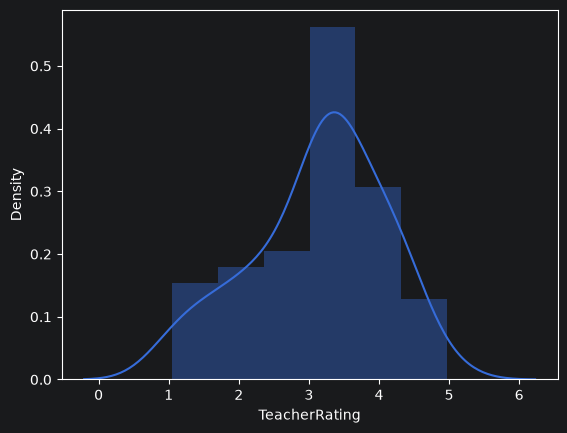

In [6]:
sns.distplot(df_teachers["TeacherRating"])

In [7]:
average_teacher_rating = df_teachers["TeacherRating"].mean().round(2)
average_teacher_rating

np.float64(3.12)

So, we see that ratings of all the instructors on EduPro platform are distributed almost uniformly (with slight variation between ratings 1 and 2). This means that there is a high concentration of teachers around average rating.

Let us also check how the instructors' age and experience are distributed.

<Axes: xlabel='Age', ylabel='Density'>

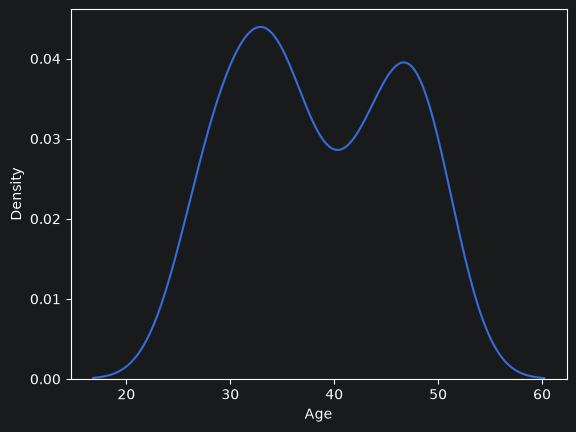

In [8]:
sns.kdeplot(df_teachers["Age"])

From the above graph, we can say that majority of teachers age between 26 and 50.

Now, let us check how well experience is distributed.

<Axes: xlabel='YearsOfExperience', ylabel='Density'>

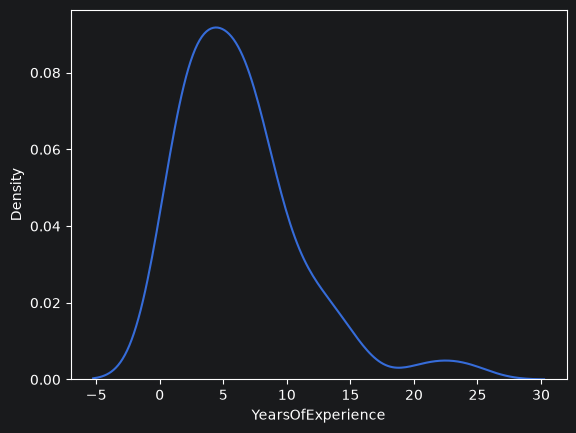

In [9]:
sns.kdeplot(df_teachers["YearsOfExperience"])

The above graph says that there are teachers with experience of less than 0 years - it starts with -5 years of experience, which does not make sense at all. Let us check our dataset again if it contains teachers with negative years of experience.

In [10]:
(df_teachers["YearsOfExperience"] < 0).sum()

np.int64(0)

Now, we see that there are no teachers with 0 years of experience. Let us check why this happened.

In [11]:
print("Number of Teachers with no experience : ",(df_teachers["YearsOfExperience"]==0).sum())
print("Number of Teachers with one year experience : ",(df_teachers["YearsOfExperience"]==1).sum())

Number of Teachers with no experience :  0
Number of Teachers with one year experience :  7


This is because the minimum experience of teachers is 1, and there are 7 teachers with one year of experience. Then until 5 years of experience, the number of teachers increase, and then the number of teachers decrease as their experience increases. This means that teachers with around 5 years of experience dominate our dataset.

Now, let us check how instructors are distributed across expertise

In [12]:
count_values = df_teachers["Expertise"].value_counts()
count_values.values

array([11,  9,  6,  6,  5,  5,  5,  5,  4,  2,  1,  1])

In [13]:
df_teachers["Expertise"]

0               Cybersecurity
1           Digital Marketing
2                      Design
3            Machine Learning
4                     Finance
5               Cybersecurity
6            Machine Learning
7                Data Science
8          Project Management
9                Data Science
10    Artificial Intelligence
11              Cybersecurity
12          Digital Marketing
13         Project Management
14               Data Science
15               Data Science
16          Digital Marketing
17         Project Management
18          Digital Marketing
19          Digital Marketing
20           Machine Learning
21          Digital Marketing
22                    Finance
23          Digital Marketing
24            Web Development
25            Web Development
26    Artificial Intelligence
27                   Business
28    Artificial Intelligence
29    Artificial Intelligence
30              Cybersecurity
31              Cybersecurity
32                     Design
33        

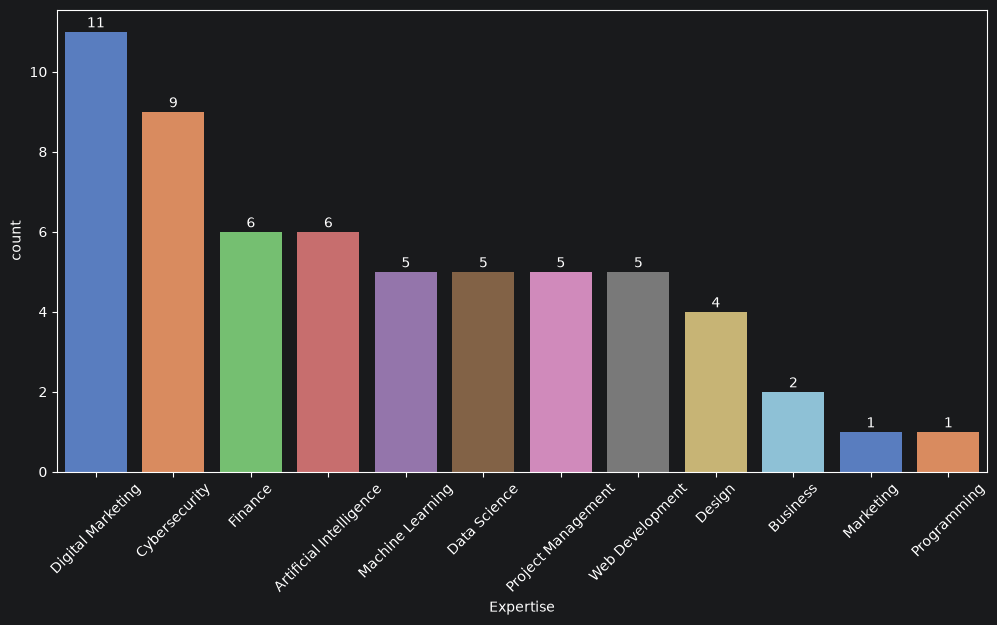

In [14]:
plt.subplots(figsize=(12,6))
count_values = df_teachers["Expertise"].value_counts()
sns.barplot(df_teachers["Expertise"].value_counts(),palette="muted")
plt.xticks(rotation=45)
for i, val in enumerate(count_values.values):
    plt.text(i,val+0.2,str(val),ha="center",va="center")

Now, let us identify who the top performers are and who the bottom ones are. For this, let us see which teachers are rated in the top 90 percentile, and those in the bottom 10 percentile

In [15]:
percentile_90 = df_teachers["TeacherRating"].quantile(0.9)
percentile_10 = df_teachers["TeacherRating"].quantile(0.1)

print("Teachers with highest ratings : ",df_teachers[(df_teachers["TeacherRating"]>percentile_90)]["TeacherName"].values.tolist())
print()
print("Teachers with lowest ratings  : ",df_teachers[(df_teachers["TeacherRating"]<percentile_10)]["TeacherName"].values.tolist())

Teachers with highest ratings :  ['Kristi Scott', 'Angela Beard', 'Debra Escobar', 'Kimberly Miller', 'Yolanda Levine', 'Aaron Kirby']

Teachers with lowest ratings  :  ['Amber Torres', 'Laurie Michael', 'Timothy Bailey', 'Brenda Mclean', 'John Williams', 'Emily Gutierrez']


Our streamlit application can contain options and sliders for various course and teacher related features, and then plot the distributions that we plotted above. So, we need to consider a function in which we consider such options and sliders as formal parameters and return the dedicated plots.

In [16]:
et = pd.merge(left=df_teachers, right=df_transactions, on="TeacherID", how="right")
df = pd.merge(left=df_courses, right=et, on="CourseID", how="right")

In [17]:
def return_plots_0(df_1,variable_to_be_analysed,**kwargs):
    return kwargs
return_plots_0(df,"Amith",CourseName="Amith",CourseCategory="Experience")

{'CourseName': 'Amith', 'CourseCategory': 'Experience'}

In [18]:
def return_plots(df_1,variable_to_be_analysed,**kwargs):
    df = df_1.copy()
    dic = kwargs.copy()
    for i in dic:
        df = df[df[i].isin(dic[i])]
    if variable_to_be_analysed == "TeacherRating":
        ot = df[["TeacherName","TeacherRating"]].drop_duplicates(ignore_index=True)
        ax1 = sns.kdeplot(ot["TeacherRating"])
    elif variable_to_be_analysed == "Age":
        ot = df[["TeacherName","Age"]].drop_duplicates(ignore_index=True)
        ax2 = sns.kdeplot(ot["Age"])
    elif variable_to_be_analysed == "YearsOfExperience":
        ot = df[["TeacherName","YearsOfExperience"]].drop_duplicates(ignore_index=True)
        ax3 = sns.kdeplot(ot["YearsOfExperience"])
    elif variable_to_be_analysed == "Expertise":
        fig,ax4 = plt.subplots(figsize=(12,6))
        count_values = df["Expertise"].value_counts()
        ax4 = sns.barplot(df["Expertise"].value_counts(),palette="muted")
        plt.xticks(rotation=45)
        for i, val in enumerate(count_values.values):
            ax4.text(i,val+0.2,str(val),ha="center",va="center")
    plt.show()
    return df

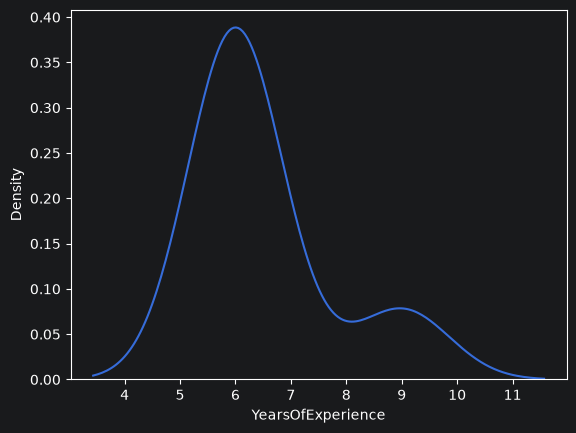

In [19]:
pl = return_plots(df_teachers,"YearsOfExperience",Expertise=["Cybersecurity","Digital Marketing"],YearsOfExperience=[6,9])

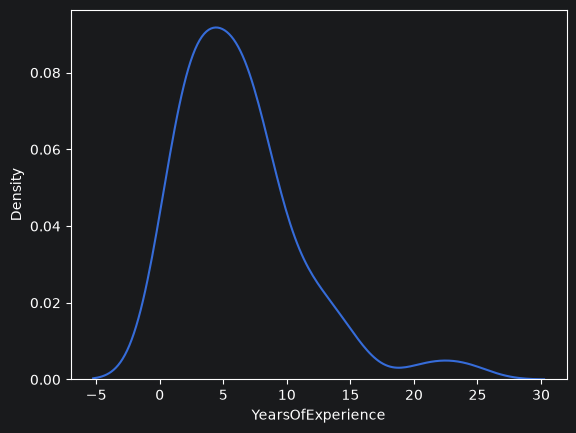

In [20]:
pe = return_plots(df_teachers,"YearsOfExperience")

Now, let us have a look at the second question - Do instructors with more experience receive higher ratings?

For this, we need to consider two variables - Years of Experience and Teacher Rating. We need to plot a graph between the variables.

In [21]:
df[["YearsOfExperience","TeacherRating"]]

,YearsOfExperience,TeacherRating
0,24,4.58
1,24,4.58
2,24,4.58
3,24,4.58
4,21,4.97
...,...,...
9995,24,4.58
9996,24,4.58
9997,24,4.58
9998,24,4.58


<Axes: xlabel='YearsOfExperience', ylabel='TeacherRating'>

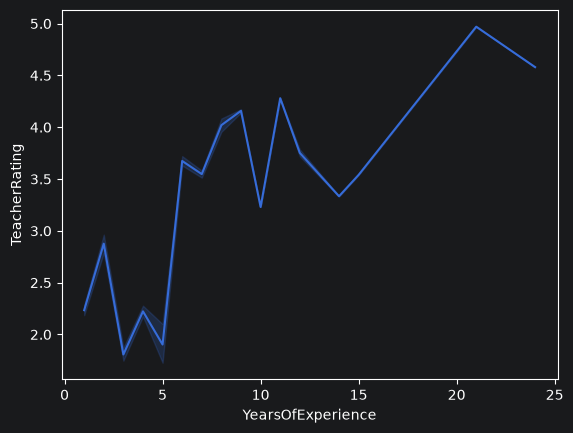

In [22]:
sns.lineplot(x=df["YearsOfExperience"],y=df["TeacherRating"])

<Axes: xlabel='YearsOfExperience', ylabel='TeacherRating'>

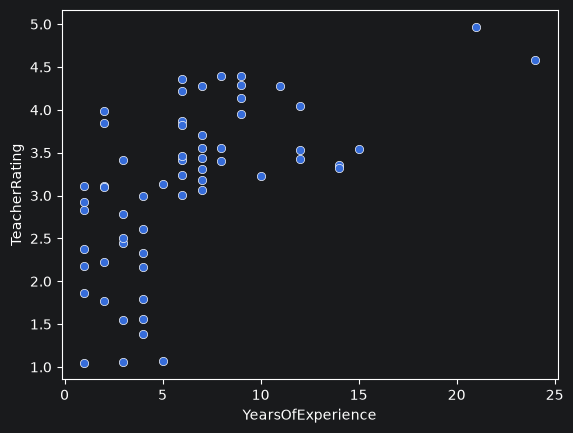

In [23]:
sns.scatterplot(x=df_teachers["YearsOfExperience"],y=df_teachers["TeacherRating"])

From the line plot, we do observe an increasing pattern in teachers' rating with respective to the experience they have, but such increase does not happen at all times. In the scatter plot, we observe teachers from 0 to 5 years of experience holding ratings at all levels - low to high. Let us find the correlation between both the variables.

In [24]:
experience_impact_score = df_teachers[["YearsOfExperience","TeacherRating"]].corr()["YearsOfExperience"].loc["TeacherRating"]
experience_impact_score

np.float64(0.5980353982941563)

We observe the correlation coefficient is around 0.598, which means that there is some relation between teacher's experience and rating. However, from the scatter plot, we observe that teachers with 0 to 5 years of experience hold ratings throughout the range, but the highly experienced ones are rated significantly high.

From this, we can infer that low experience does not lead to lower ratings, but experienced ones always get higher ratings. So, the answer to the question is Yes - instructors with more experience do receive higher ratings.

Now, let us have a look at the third question - Is there a relationship between TeacherRating and CourseRating?

Teacher Rating is from Teachers dataset, and Course Rating is from Courses dataset.

We already had a look at the Teachers dataset.

Now, let us have a look at the Courses dataset.

In [25]:
df_courses.head()

,CourseID,CourseName,CourseCategory,CourseType,CourseLevel,CoursePrice,CourseDuration,CourseRating
0,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.00,4.74
1,CR00002,Java Programming,Programming,Free,Intermediate,0.00,37.70,2.43
2,CR00003,C++ for Beginners,Programming,Free,Beginner,0.00,19.53,3.85
3,CR00004,Advanced Python,Programming,Free,Beginner,0.00,45.13,2.88
4,CR00005,Full Stack Development,Programming,Free,Beginner,0.00,28.68,1.28


In [26]:
print("Columns in Teachers dataset : ",df_teachers.columns)
print()
print("Columns in Courses dataset  : ",df_courses.columns)

Columns in Teachers dataset :  Index(['TeacherID', 'TeacherName', 'Age', 'Gender', 'Expertise',
       'YearsOfExperience', 'TeacherRating'],
      dtype='str')

Columns in Courses dataset  :  Index(['CourseID', 'CourseName', 'CourseCategory', 'CourseType', 'CourseLevel',
       'CoursePrice', 'CourseDuration', 'CourseRating'],
      dtype='str')


The above two datasets do not have a common column at all. So, we need to have a look at a third dataset that can combine these two datasets. The third dataset should have a common column with Teachers dataset, and a common one with Courses dataset. Let us have a look at the Transactions dataset.

In [27]:
df_transactions.head()

,TransactionID,UserID,CourseID,TransactionDate,Amount,PaymentMethod,TeacherID
0,TT00001,U00003,CR00016,25/10/2025,0.0,PayPal,TC00040
1,TT00002,U00003,CR00037,13/1/2025,0.0,PayPal,TC00040
2,TT00003,U00003,CR00019,28/3/2025,0.0,Bank Transfer,TC00040
3,TT00004,U00004,CR00048,2/6/2025,0.0,Bank Transfer,TC00040
4,TT00005,U00004,CR00060,10/8/2025,0.0,PayPal,TC00042


In [28]:
print("Columns in Teachers dataset : ",df_teachers.columns)
print()
print("Columns in Courses dataset  : ",df_courses.columns)
print()
print("Columns in Transactions dataset  : ",df_transactions.columns)

Columns in Teachers dataset :  Index(['TeacherID', 'TeacherName', 'Age', 'Gender', 'Expertise',
       'YearsOfExperience', 'TeacherRating'],
      dtype='str')

Columns in Courses dataset  :  Index(['CourseID', 'CourseName', 'CourseCategory', 'CourseType', 'CourseLevel',
       'CoursePrice', 'CourseDuration', 'CourseRating'],
      dtype='str')

Columns in Transactions dataset  :  Index(['TransactionID', 'UserID', 'CourseID', 'TransactionDate', 'Amount',
       'PaymentMethod', 'TeacherID'],
      dtype='str')


We can notice that there is one column in the Transactions dataset that is in common with Teachers dataset (TeacherID), and one column that is common with the Courses dataset (CourseID). So let us now combine these three datasets into one.

In [29]:
et = pd.merge(left=df_teachers, right=df_transactions, on="TeacherID", how="right")
df = pd.merge(left=df_courses, right=et, on="CourseID", how="right")
df.sort_values(by="CourseID",inplace=True,ignore_index=True)

In [30]:
df.head()

,CourseID,CourseName,CourseCategory,CourseType,CourseLevel,CoursePrice,CourseDuration,CourseRating,TeacherID,TeacherName,Age,Gender,Expertise,YearsOfExperience,TeacherRating,TransactionID,UserID,TransactionDate,Amount,PaymentMethod
0,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.0,4.74,TC00042,Yolanda Levine,49,Female,Machine Learning,21,4.97,TT00021,U00018,24/3/2025,472.28,PayPal
1,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.0,4.74,TC00040,Kimberly Miller,49,Male,Cybersecurity,24,4.58,TT00061,U00117,28/11/2025,472.28,PayPal
2,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.0,4.74,TC00042,Yolanda Levine,49,Female,Machine Learning,21,4.97,TT00085,U00147,14/11/2025,472.28,Credit Card
3,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.0,4.74,TC00042,Yolanda Levine,49,Female,Machine Learning,21,4.97,TT00090,U00152,5/11/2025,472.28,Credit Card
4,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.0,4.74,TC00040,Kimberly Miller,49,Male,Cybersecurity,24,4.58,TT00144,U00238,24/8/2025,472.28,PayPal


Now, since we combined three datasets, let us get into our problem - "Is there a relationship between TeacherRating and CourseRating?"

For this, we need to construct a scatter plot, and calculate the correlation coefficient between two features

<Axes: xlabel='TeacherRating', ylabel='CourseRating'>

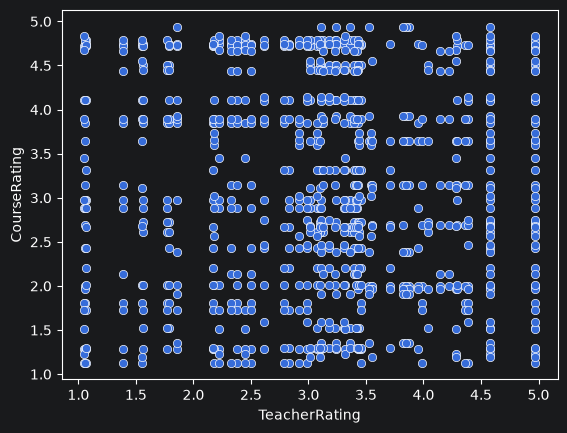

In [31]:
puf = df[["TeacherRating","CourseRating"]].drop_duplicates()

sns.scatterplot(x=puf["TeacherRating"],y=puf["CourseRating"])

In [32]:
puf.drop_duplicates().corr()["TeacherRating"].loc["CourseRating"]

np.float64(-0.03347950418044099)

The scatter plot displays all the points taking over the entire graph, which means that a course of any quality, it can be taught by teacher holding any rating.

For example, if a course has a rating of 1.0, it can be taught by a teacher of any rating. Similarly, if a course is of rating 2.0, it can be taught be a teacher of any rating.

In other words, we can say that course rating is no way related to teacher rating.

To support our argument, we also found out that the correlation of teacher rating with course rating is close to zero.

So, for the question - "Is there a relationship between TeacherRating and CourseRating?", the answer would be No.

Let us find out how correlated the teacher experience is with respect to course rating

<Axes: xlabel='YearsOfExperience', ylabel='CourseRating'>

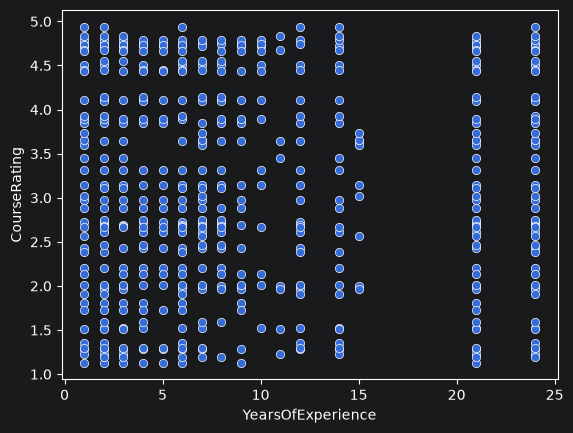

In [33]:
guf = df[["YearsOfExperience","CourseRating"]].drop_duplicates()

sns.scatterplot(x=guf["YearsOfExperience"],y=guf["CourseRating"])

In [34]:
guf.drop_duplicates().corr()["YearsOfExperience"].loc["CourseRating"]

np.float64(0.006123910319907878)

We observe the same pattern between years of experience held by teachers and course rating as we observed with teacher rating vs course rating - points taking over the entire dataset. This means that a teacher with any experience can hold any rating - There is no guarantee that a high-quality course can be dealt by a highly experienced person. Even our near-zero correlation coefficient supports this.

Let us construct heatmaps among years of experience, course rating and teacher rating

<Axes: >

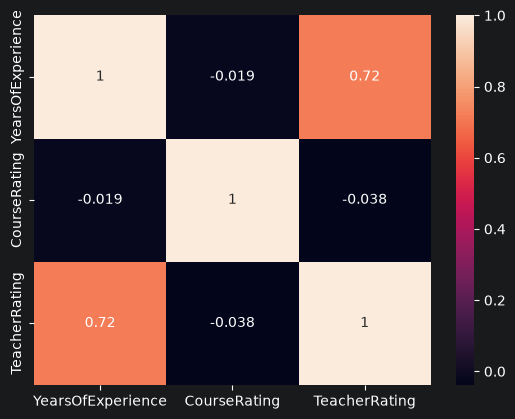

In [35]:
tuf = df[["YearsOfExperience","CourseRating","TeacherRating"]].drop_duplicates()

sns.heatmap(tuf.corr(),annot=True)

Now, let us evaluate the quality of courses by category and level

**Evaluating quality of courses by category**

In [36]:
category_vs_rating = df[["CourseName","CourseCategory","CourseRating"]].drop_duplicates(ignore_index=True)
category_vs_rating["Number"] = 0
for i in category_vs_rating["CourseCategory"].unique():
    pu = category_vs_rating[category_vs_rating["CourseCategory"] == i]
    ctr = 0
    for j in pu.index:
        category_vs_rating.loc[j,"Number"] = ctr
        ctr += 1

<Axes: xlabel='Number', ylabel='CourseRating'>

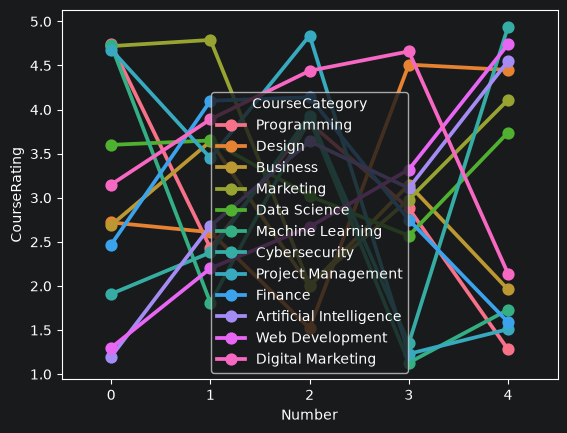

In [37]:

pu = category_vs_rating.copy()

sns.pointplot(x=pu["Number"],y=pu["CourseRating"],hue=pu["CourseCategory"])#,drawstyle="steps-post",)

In [38]:
each_category = pd.DataFrame(columns=["CourseCategory","LeastRating","HighestRating","AverageRating"])
each_category["CourseCategory"] = category_vs_rating["CourseCategory"].unique()
least_ratings = []
highest_ratings = []
avg_ratings = []
ctr = 0
for i in category_vs_rating["CourseCategory"].unique():
    least_rating = category_vs_rating[category_vs_rating["CourseCategory"] == i]["CourseRating"].min()
    highest_rating = category_vs_rating[category_vs_rating["CourseCategory"] == i]["CourseRating"].max()
    avg_rating = category_vs_rating[category_vs_rating["CourseCategory"] == i]["CourseRating"].mean()

    least_ratings.append(least_rating)
    highest_ratings.append(highest_rating)
    avg_ratings.append(avg_rating)

each_category["LeastRating"] = least_ratings
each_category["HighestRating"] = highest_ratings
each_category["AverageRating"] = avg_ratings

In [39]:
def return_category_vs_rating(df_1,display_graph=False,ax=None,**kwargs):
    df = df_1.copy()
    dic = kwargs.copy()
    for i in dic:
        df = df[df[i].isin(dic[i])]

    category_vs_rating = df[["CourseCategory","CourseRating"]].drop_duplicates(ignore_index=True)
    category_vs_rating["Number"] = 0
    for i in category_vs_rating["CourseCategory"].unique():
        pu = category_vs_rating[category_vs_rating["CourseCategory"] == i]
        ctr = 0
        for j in pu.index:
            category_vs_rating.loc[j,"Number"] = ctr
            ctr += 1

    each_category = pd.DataFrame(columns=["CourseCategory","LeastRating","HighestRating","AverageRating"])
    each_category["CourseCategory"] = category_vs_rating["CourseCategory"].unique()

    least_ratings = []
    highest_ratings = []
    avg_ratings = []
    ctr = 0
    for i in category_vs_rating["CourseCategory"].unique():
        least_rating = category_vs_rating[category_vs_rating["CourseCategory"] == i]["CourseRating"].min()
        highest_rating = category_vs_rating[category_vs_rating["CourseCategory"] == i]["CourseRating"].max()
        avg_rating = category_vs_rating[category_vs_rating["CourseCategory"] == i]["CourseRating"].mean()

        least_ratings.append(least_rating)
        highest_ratings.append(highest_rating)
        avg_ratings.append(avg_rating)

    each_category["LeastRating"] = least_ratings
    each_category["HighestRating"] = highest_ratings
    each_category["AverageRating"] = avg_ratings
    if display_graph == True:
        if ax is None:
            sns.pointplot(x=category_vs_rating["Number"],y=category_vs_rating["CourseRating"],hue=category_vs_rating["CourseCategory"],lw=4)
        else:
            sns.pointplot(x=category_vs_rating["Number"],y=category_vs_rating["CourseRating"],hue=category_vs_rating["CourseCategory"],lw=4,ax=ax)
        for i, val in zip(category_vs_rating["Number"].values,category_vs_rating["CourseRating"].values):
            plt.text(i,val+0.2,str(val),ha="center",va="top",fontsize=6)
        plt.xticks([])
        plt.xlabel(None)
        plt.show()

    return category_vs_rating, each_category, df

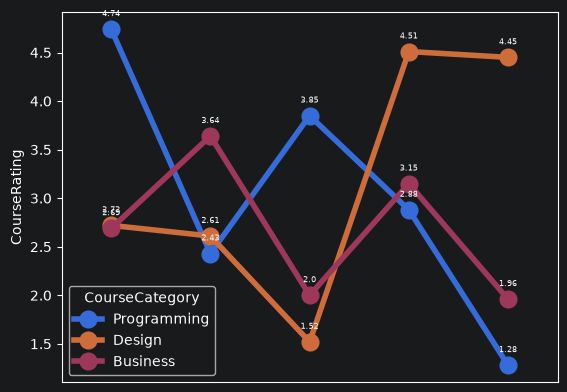

In [40]:
cvr, ec, dd = return_category_vs_rating(df,True,CourseCategory=['Programming','Design','Business'])

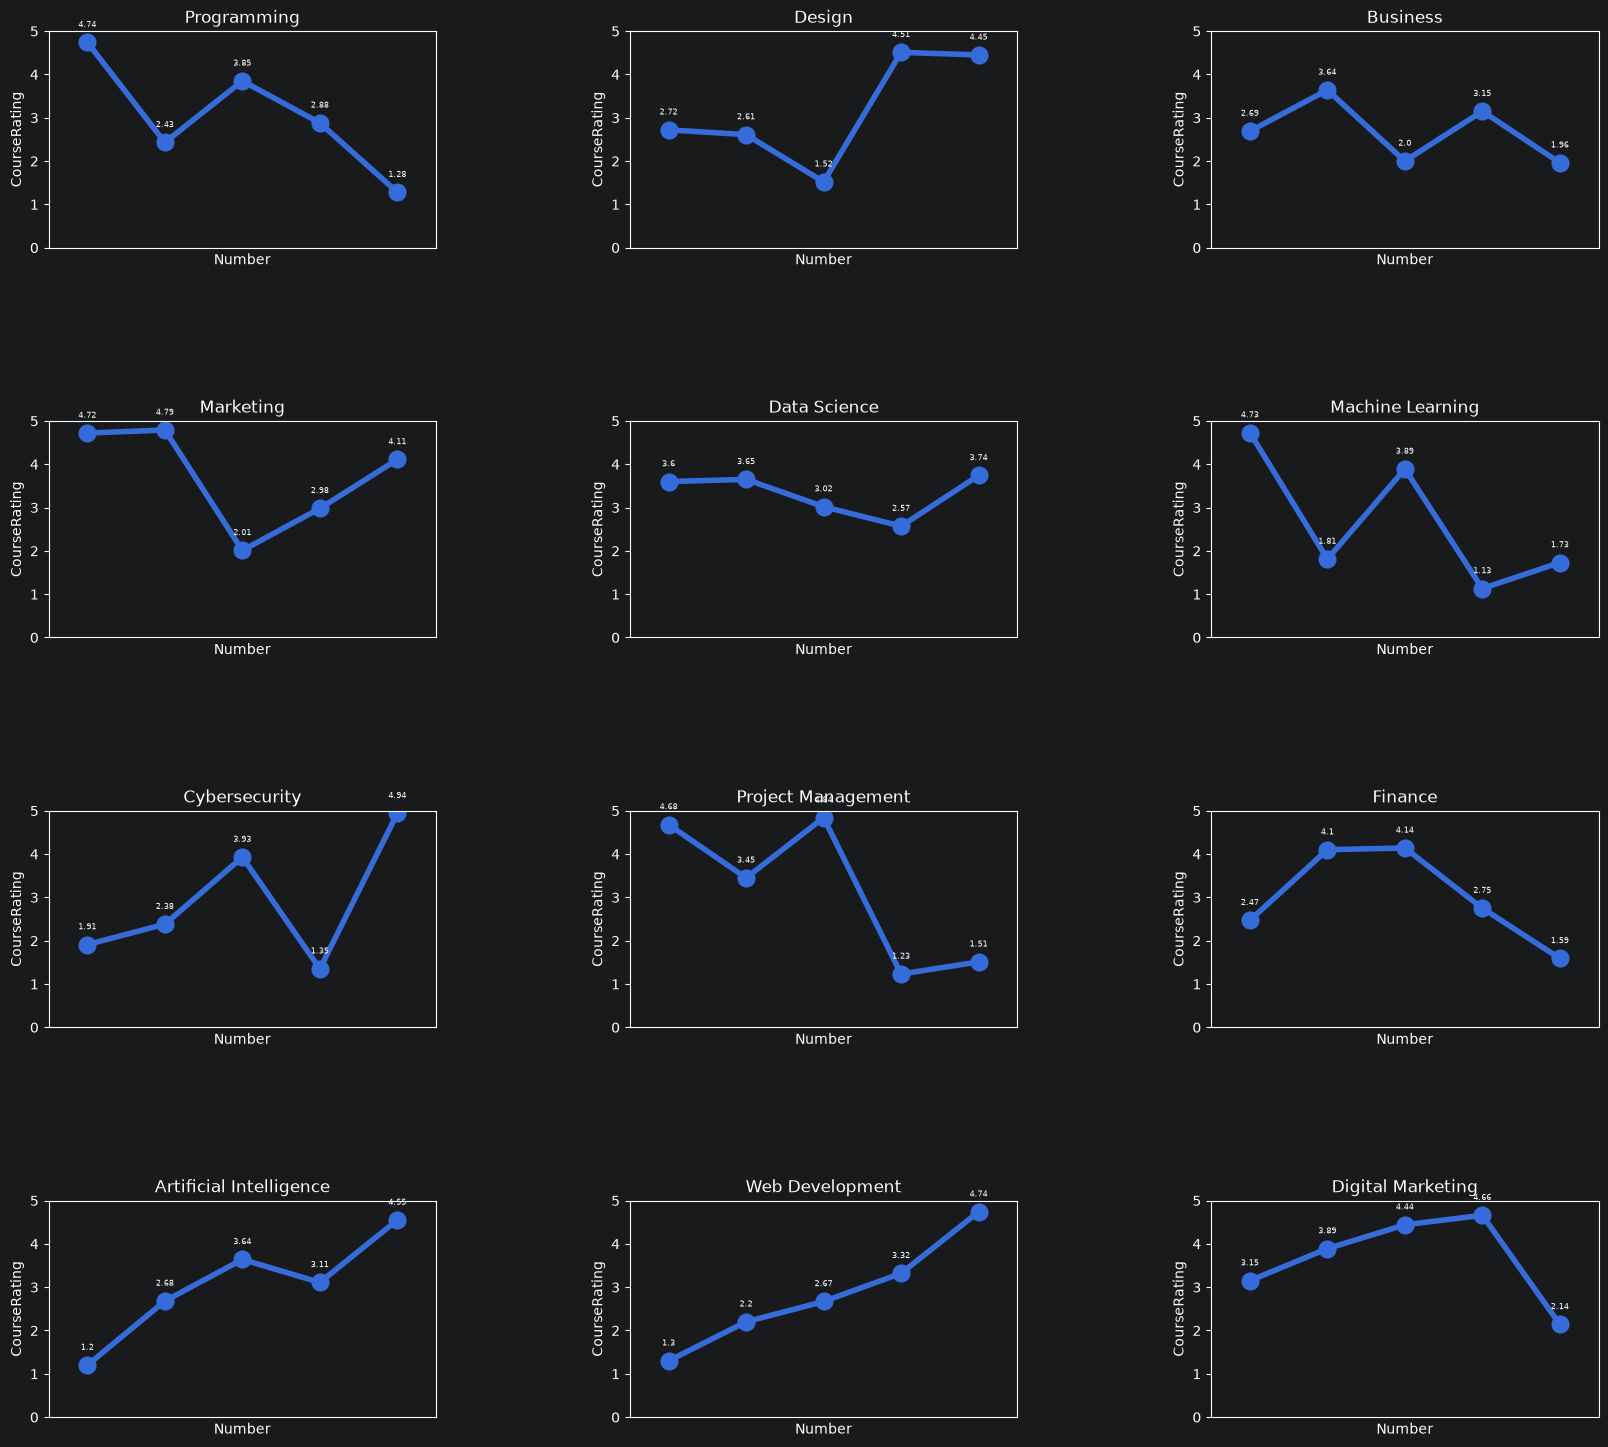

In [41]:

category_vs_rating = df[["CourseCategory","CourseRating"]].drop_duplicates(ignore_index=True)
category_vs_rating["Number"] = 0
for i in category_vs_rating["CourseCategory"].unique():
    pu = category_vs_rating[category_vs_rating["CourseCategory"] == i]
    ctr = 0
    for j in pu.index:
        category_vs_rating.loc[j,"Number"] = ctr
        ctr += 1

nrows = 4
ncols = len(df["CourseCategory"].unique())//nrows

list_of_course_categories = df["CourseCategory"].unique()

fig, ax = plt.subplots(nrows=nrows,ncols=ncols,figsize=(20,18))
fig.subplots_adjust(hspace=0.8, wspace=0.5)

ctr = 0
for (i,j) in list(itertools.product(range(nrows),range(ncols))):
    course_category = list_of_course_categories[ctr]
    lf = category_vs_rating[category_vs_rating["CourseCategory"]==course_category].reset_index(drop=True)
    sns.pointplot(x=lf["Number"],y=lf["CourseRating"],lw=4,ax=ax[i,j])
    for k, val in zip(lf["Number"].values,lf["CourseRating"].values):
        ax[i,j].text(k,val+0.5,str(val),ha="center",va="top",fontsize=6)
    #lf = df[df["CourseCategory"]==course_category]["CourseRating"].reset_index(drop=True)
    #lf = df[df["CourseCategory"]==course_category][["CourseName","CourseRating"]].drop_duplicates(ignore_index=True)
    # cvr, ec, dd = return_category_vs_rating(df,True,ax=ax[i,j],CourseCategory=[course_category])#,drawstyle="steps-post",lw=4)
    ax[i,j].set_title(course_category)
    ax[i,j].set_xticks([])
    ax[i,j].set_ylim(0,5)

    #ax[ctr] = sns.pointplot(lf)
    #
    ctr += 1

In [42]:
rating_consistency_index = category_vs_rating.groupby(by="CourseCategory")["CourseRating"].std().round(2)
rating_consistency_index


CourseCategory
Artificial Intelligence    1.24
Business                   0.73
Cybersecurity              1.49
Data Science               0.50
Design                     1.29
Digital Marketing          1.03
Finance                    1.10
Machine Learning           1.56
Marketing                  1.20
Programming                1.33
Project Management         1.71
Web Development            1.29
Name: CourseRating, dtype: float64

**Evaluating quality of courses by level**

In [43]:
level_vs_rating = df[["CourseName","CourseLevel","CourseRating"]].drop_duplicates(ignore_index=True)
tu = []
level_vs_rating["Number"] = 0
for i in level_vs_rating["CourseLevel"].unique():
    pu = level_vs_rating[level_vs_rating["CourseLevel"] == i]
    ctr = 0
    for j in pu.index:
        level_vs_rating.loc[j,"Number"] = ctr
        ctr += 1
level_vs_rating

,CourseName,CourseLevel,CourseRating,Number
0,Python Basics,Beginner,4.74,0
1,Java Programming,Intermediate,2.43,0
2,C++ for Beginners,Beginner,3.85,1
3,Advanced Python,Beginner,2.88,2
4,Full Stack Development,Beginner,1.28,3
5,Graphic Design Basics,Advanced,2.72,0
6,UI/UX Design,Advanced,2.61,1
7,Photoshop Mastery,Advanced,1.52,2
8,Web Design Fundamentals,Beginner,4.51,4
9,3D Modeling,Advanced,4.45,3


In [44]:
each_level = pd.DataFrame(columns=["CourseLevel","LeastRating","HighestRating","AverageRating"])
each_level["CourseLevel"] = df["CourseLevel"].unique()
least_ratings = []
highest_ratings = []
avg_ratings = []
ctr = 0
for i in df["CourseLevel"].unique():
    least_rating = df[df["CourseLevel"] == i]["CourseRating"].min()
    highest_rating = df[df["CourseLevel"] == i]["CourseRating"].max()
    avg_rating = df[df["CourseLevel"] == i]["CourseRating"].mean()

    least_ratings.append(least_rating)
    highest_ratings.append(highest_rating)
    avg_ratings.append(avg_rating)

each_level["LeastRating"] = least_ratings
each_level["HighestRating"] = highest_ratings
each_level["AverageRating"] = avg_ratings

In [45]:
def return_level_vs_rating(df_1,display_graph=False,**kwargs):
    df = df_1.copy()
    dic = kwargs.copy()
    for i in dic:
        df = df[df[i].isin(dic[i])]

    level_vs_rating = df[["CourseName","CourseLevel","CourseRating"]].drop_duplicates(ignore_index=True)
    level_vs_rating["Number"] = 0
    for i in level_vs_rating["CourseLevel"].unique():
        pu = level_vs_rating[level_vs_rating["CourseLevel"] == i]
        ctr = 0
        for j in pu.index:
            level_vs_rating.loc[j,"Number"] = ctr
            ctr += 1

    each_level = pd.DataFrame(columns=["CourseLevel","LeastRating","HighestRating","AverageRating"])
    each_level["CourseLevel"] = df["CourseLevel"].unique()
    least_ratings = []
    highest_ratings = []
    avg_ratings = []
    ctr = 0
    for i in df["CourseLevel"].unique():
        least_rating = df[df["CourseLevel"] == i]["CourseRating"].min()
        highest_rating = df[df["CourseLevel"] == i]["CourseRating"].max()
        avg_rating = df[df["CourseLevel"] == i]["CourseRating"].mean()

        least_ratings.append(least_rating)
        highest_ratings.append(highest_rating)
        avg_ratings.append(avg_rating)

    each_level["LeastRating"] = least_ratings
    each_level["HighestRating"] = highest_ratings
    each_level["AverageRating"] = avg_ratings

    if display_graph == True:
        #sns.lineplot(x=level_vs_rating["Number"],y=level_vs_rating["CourseRating"],hue=level_vs_rating["CourseLevel"],drawstyle="steps-post",lw=4)
        sns.pointplot(x=level_vs_rating["Number"],y=level_vs_rating["CourseRating"],hue=level_vs_rating["CourseLevel"],lw=4)
        plt.xticks([])
        plt.xlabel(None)
        plt.show()

    return level_vs_rating, each_level, df

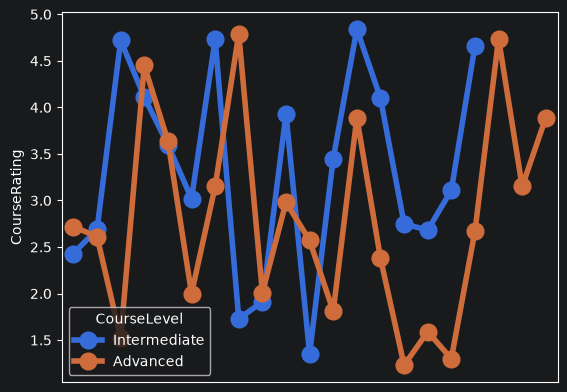

In [46]:
lvr, el, ll = return_level_vs_rating(df,display_graph=True,CourseLevel=["Intermediate","Advanced"])

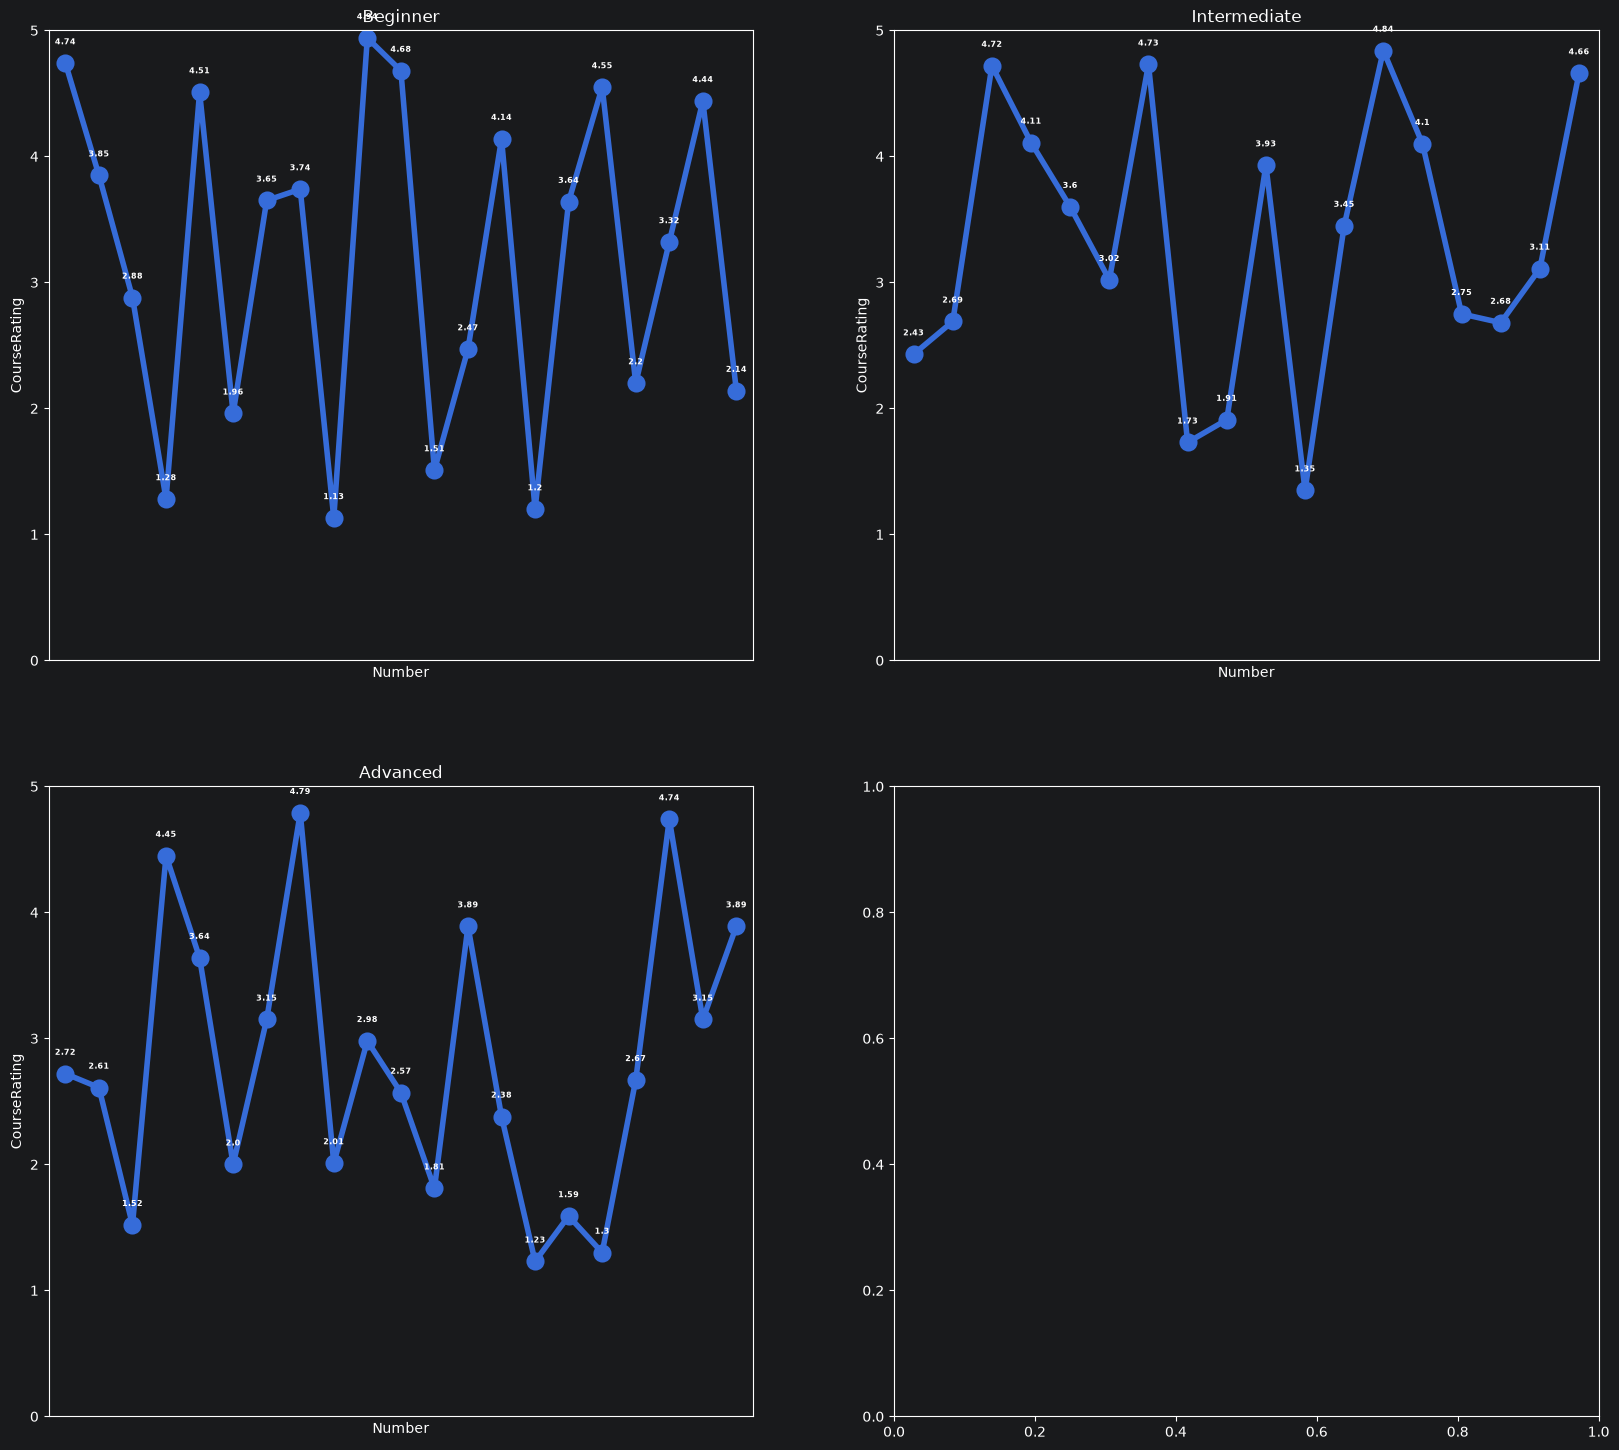

In [47]:
level_vs_rating = df[["CourseName","CourseLevel","CourseRating"]].drop_duplicates(ignore_index=True)
tu = []
level_vs_rating["Number"] = 0
for i in level_vs_rating["CourseLevel"].unique():
    pu = level_vs_rating[level_vs_rating["CourseLevel"] == i]
    ctr = 0
    for j in pu.index:
        level_vs_rating.loc[j,"Number"] = ctr
        ctr += 1

nrows = 2
ncols = 2

list_of_course_levels = level_vs_rating["CourseLevel"].unique()

fig, ax = plt.subplots(nrows=nrows,ncols=ncols,figsize=(20,18))
#fig.subplots_adjust(hspace=0.8, wspace=0.5)

ctr = 0
for (i,j) in list(itertools.product(range(nrows),range(ncols))):
    course_level = list_of_course_levels[ctr]
    lf = level_vs_rating[level_vs_rating["CourseLevel"]==course_level].reset_index(drop=True)
    sns.pointplot(x=lf["Number"],y=lf["CourseRating"],lw=4,ax=ax[i,j])
    for k, val in zip(lf["Number"].values,lf["CourseRating"].values):
        ax[i,j].text(k,val+0.2,str(val),ha="center",va="top",fontsize=6,fontweight="bold")
    #lf = df[df["CourseCategory"]==course_category]["CourseRating"].reset_index(drop=True)
    #lf = df[df["CourseCategory"]==course_category][["CourseName","CourseRating"]].drop_duplicates(ignore_index=True)
    # cvr, ec, dd = return_category_vs_rating(df,True,ax=ax[i,j],CourseCategory=[course_category])#,drawstyle="steps-post",lw=4)
    ax[i,j].set_title(course_level)
    ax[i,j].set_xticks([])
    ax[i,j].set_ylim(0,5)

    #ax[ctr] = sns.pointplot(lf)
    #
    ctr += 1
    if ctr == 3:
        break

**Comparing Gender and Course level**

In [48]:
gender_vs_level = df[["Gender","CourseLevel"]].value_counts().reset_index().sort_values(by=["Gender"])

gender_vs_level["Order-1"] = list(map(lambda x: 0 if x == "Female" else 1,gender_vs_level["Gender"]))
gender_vs_level["Order-2"] = list(map(lambda x: 0 if x == "Beginner" else (1 if x == "Intermediate" else 2),gender_vs_level["CourseLevel"]))
gender_vs_level.sort_values(by=["Order-1","Order-2"],inplace=True,ignore_index=True)
gender_vs_level = gender_vs_level.drop(columns=["Order-1","Order-2"])
gender_vs_level

,Gender,CourseLevel,count
0,Female,Beginner,1724
1,Female,Intermediate,1414
2,Female,Advanced,1788
3,Male,Beginner,1849
4,Male,Intermediate,1538
5,Male,Advanced,1687


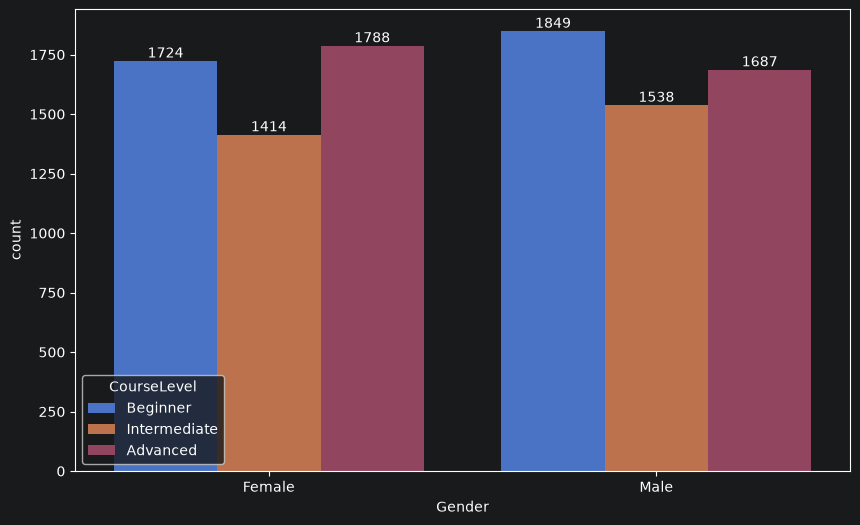

In [49]:
plt.figure(figsize=(10,6))
ax = sns.barplot(x=gender_vs_level["Gender"],y=gender_vs_level["count"],hue=gender_vs_level["CourseLevel"])
sns.move_legend(ax,loc="lower left")
for i in ax.containers:
    ax.bar_label(container=i)

From the above graph, we can say that there is small significance of differences in both males and females attending courses at three levels. Most of the females attend advanced courses, while most males attend beginner courses. Males dominate females at beginner and intermediate levels, while it is the other way around at advanced level.

**Identification of categories with consistently high or low ratings**

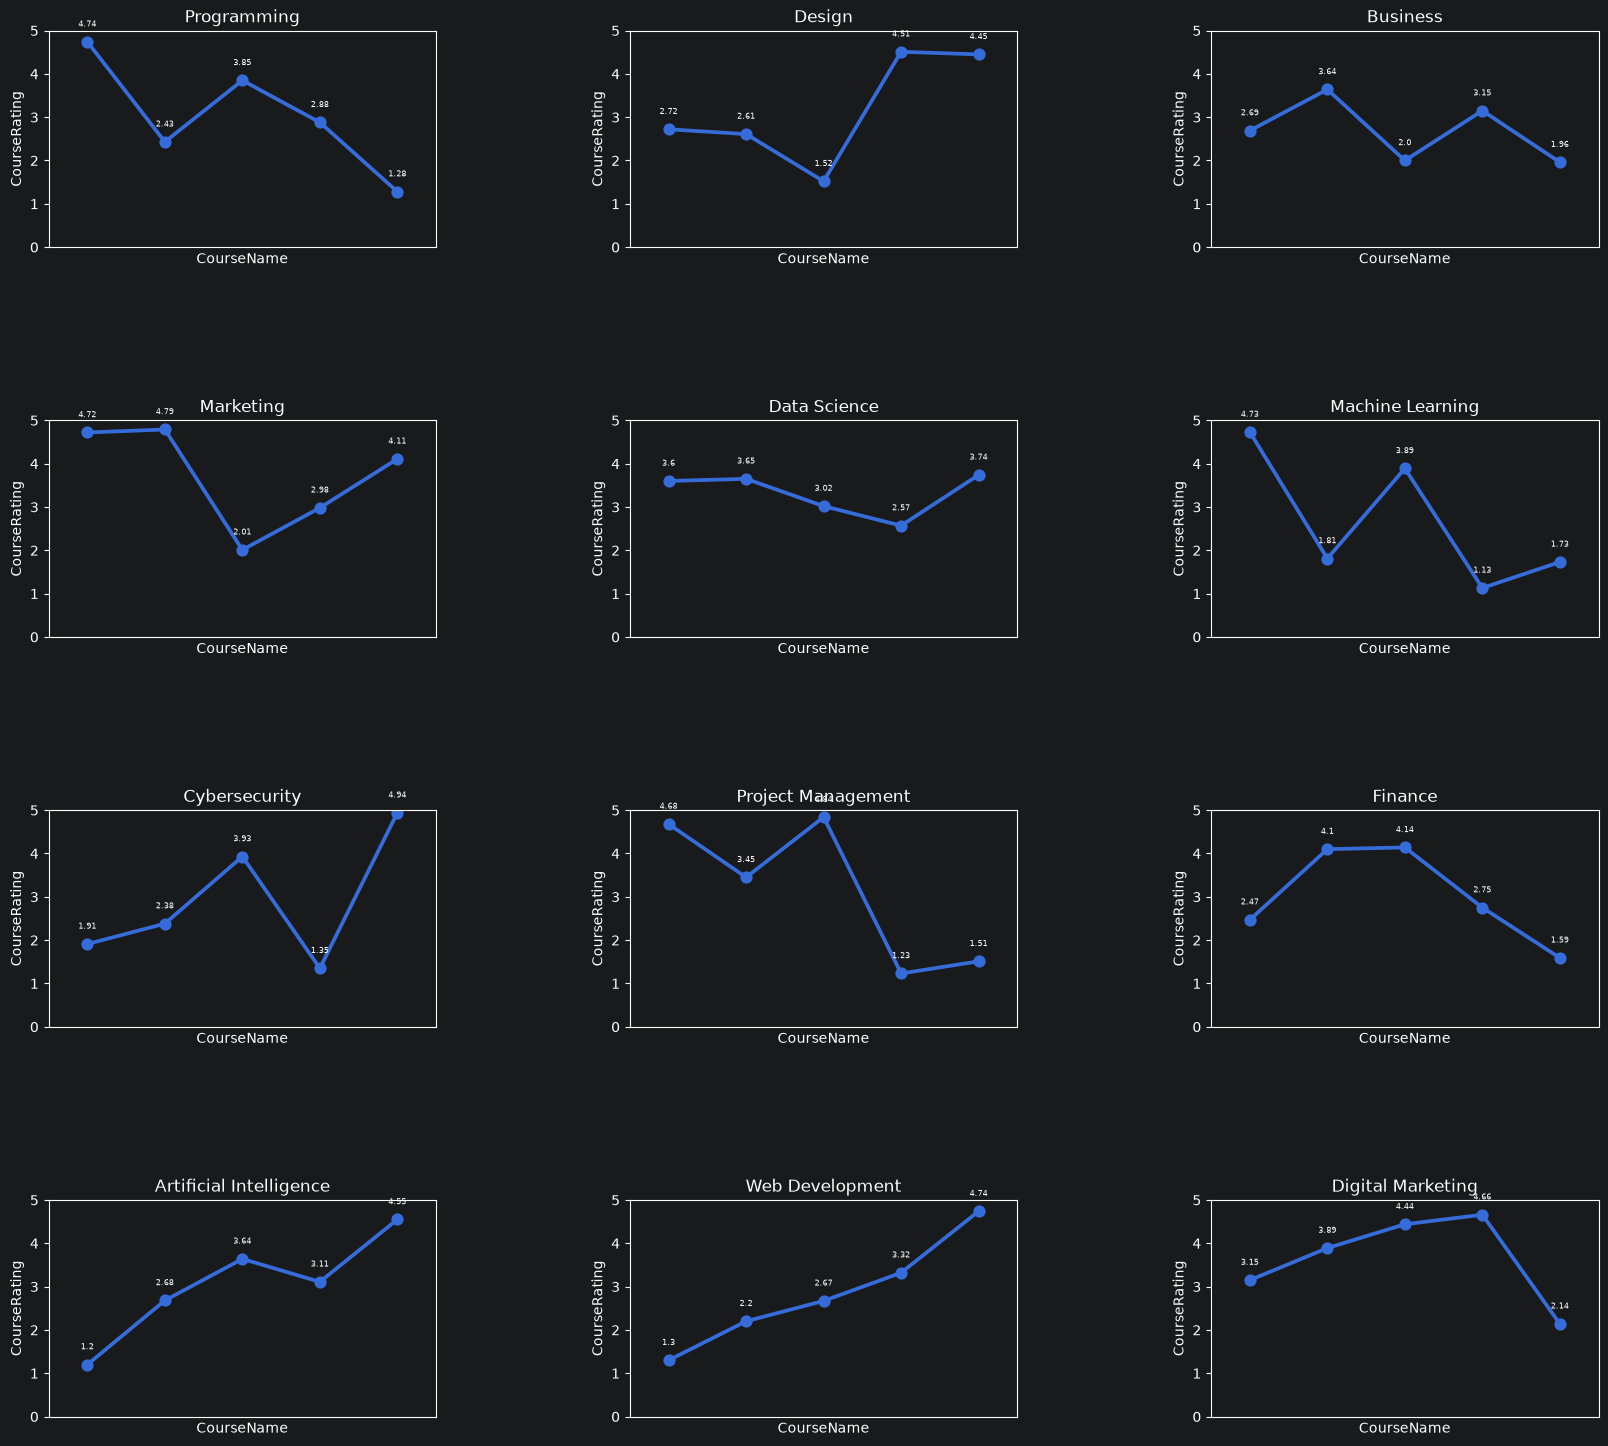

In [50]:
nrows = 4
ncols = len(df["CourseCategory"].unique())//nrows

list_of_course_categories = df["CourseCategory"].unique()

# fig, ax = plt.subplots(nrows=len(list_of_course_categories),ncols=1,figsize=(20,10))
fig, ax = plt.subplots(nrows=nrows,ncols=ncols,figsize=(20,18))
fig.subplots_adjust(hspace=0.8, wspace=0.5)

ctr = 0
for (i,j) in list(itertools.product(range(nrows),range(ncols))):
    course_category = list_of_course_categories[ctr]
    #lf = df[df["CourseCategory"]==course_category]["CourseRating"].reset_index(drop=True)
    lf = df[df["CourseCategory"]==course_category][["CourseName","CourseRating"]].drop_duplicates(ignore_index=True)
    sns.pointplot(x=lf["CourseName"],y=lf["CourseRating"],ax=ax[i,j])#,drawstyle="steps-post",lw=4)
    for k, val in zip(lf["CourseName"].values,lf["CourseRating"].values):
        ax[i,j].text(k,val+0.5,str(val),ha="center",va="top",fontsize=6)
    ax[i,j].set_title(course_category)
    ax[i,j].set_xticks([])
    ax[i,j].set_ylim(0,5)

    #ax[ctr] = sns.pointplot(lf)
    #
    ctr += 1

As we have a look at the above graphs, all the domains provide courses of varying quality. Each domain provides at least one course of low quality, and at least one course of high quality.

As we have a look at the above graphs, some categories trend up (AI, Web Development), some trend down (Project Management, Marketing), and others fluctuate (Machine Learning, Cybersecurity). Note the y-axes differ across plots, so compare levels carefully.

Here, we can consider a key performance indicator called Rating Consistency Index, which is the measure of how consistent our ratings are for each category. It is basically the standard deviation of all ratings.

In [51]:
rating_consistency_index = category_vs_rating.groupby(by="CourseCategory")["CourseRating"].std().round(2)
rating_consistency_index

CourseCategory
Artificial Intelligence    1.24
Business                   0.73
Cybersecurity              1.49
Data Science               0.50
Design                     1.29
Digital Marketing          1.03
Finance                    1.10
Machine Learning           1.56
Marketing                  1.20
Programming                1.33
Project Management         1.71
Web Development            1.29
Name: CourseRating, dtype: float64

Data Science has the rating consistency index the least compared to other courses. This means that the quality of Data Science courses is almost consistent.

**Comparison of Course Ratings for instructors of various ratings**

Here, we will divide the teacher ratings into three categories - high rating (rating above 4), mid rating (rating from 2 to 4), and low rating (below 2). We will consider these datasets and then plot graphs for each of these.

In [52]:
df[df["TeacherRating"]>=4][["CourseName","CourseRating"]].drop_duplicates(ignore_index=True)

,CourseName,CourseRating
0,Python Basics,4.74
1,Java Programming,2.43
2,C++ for Beginners,3.85
3,Advanced Python,2.88
4,Full Stack Development,1.28
5,Graphic Design Basics,2.72
6,UI/UX Design,2.61
7,Photoshop Mastery,1.52
8,Web Design Fundamentals,4.51
9,3D Modeling,4.45


In [53]:
high_rated_teachers = df[df["TeacherRating"]>=4][["CourseName","CourseRating"]].drop_duplicates(ignore_index=True)
mid_rated_teachers = df[(df["TeacherRating"]>=2) & (df["TeacherRating"]<4)][["CourseName","CourseRating"]].drop_duplicates(ignore_index=True)
low_rated_teachers = df[df["TeacherRating"]<2][["CourseName","CourseRating"]].drop_duplicates(ignore_index=True)

[]

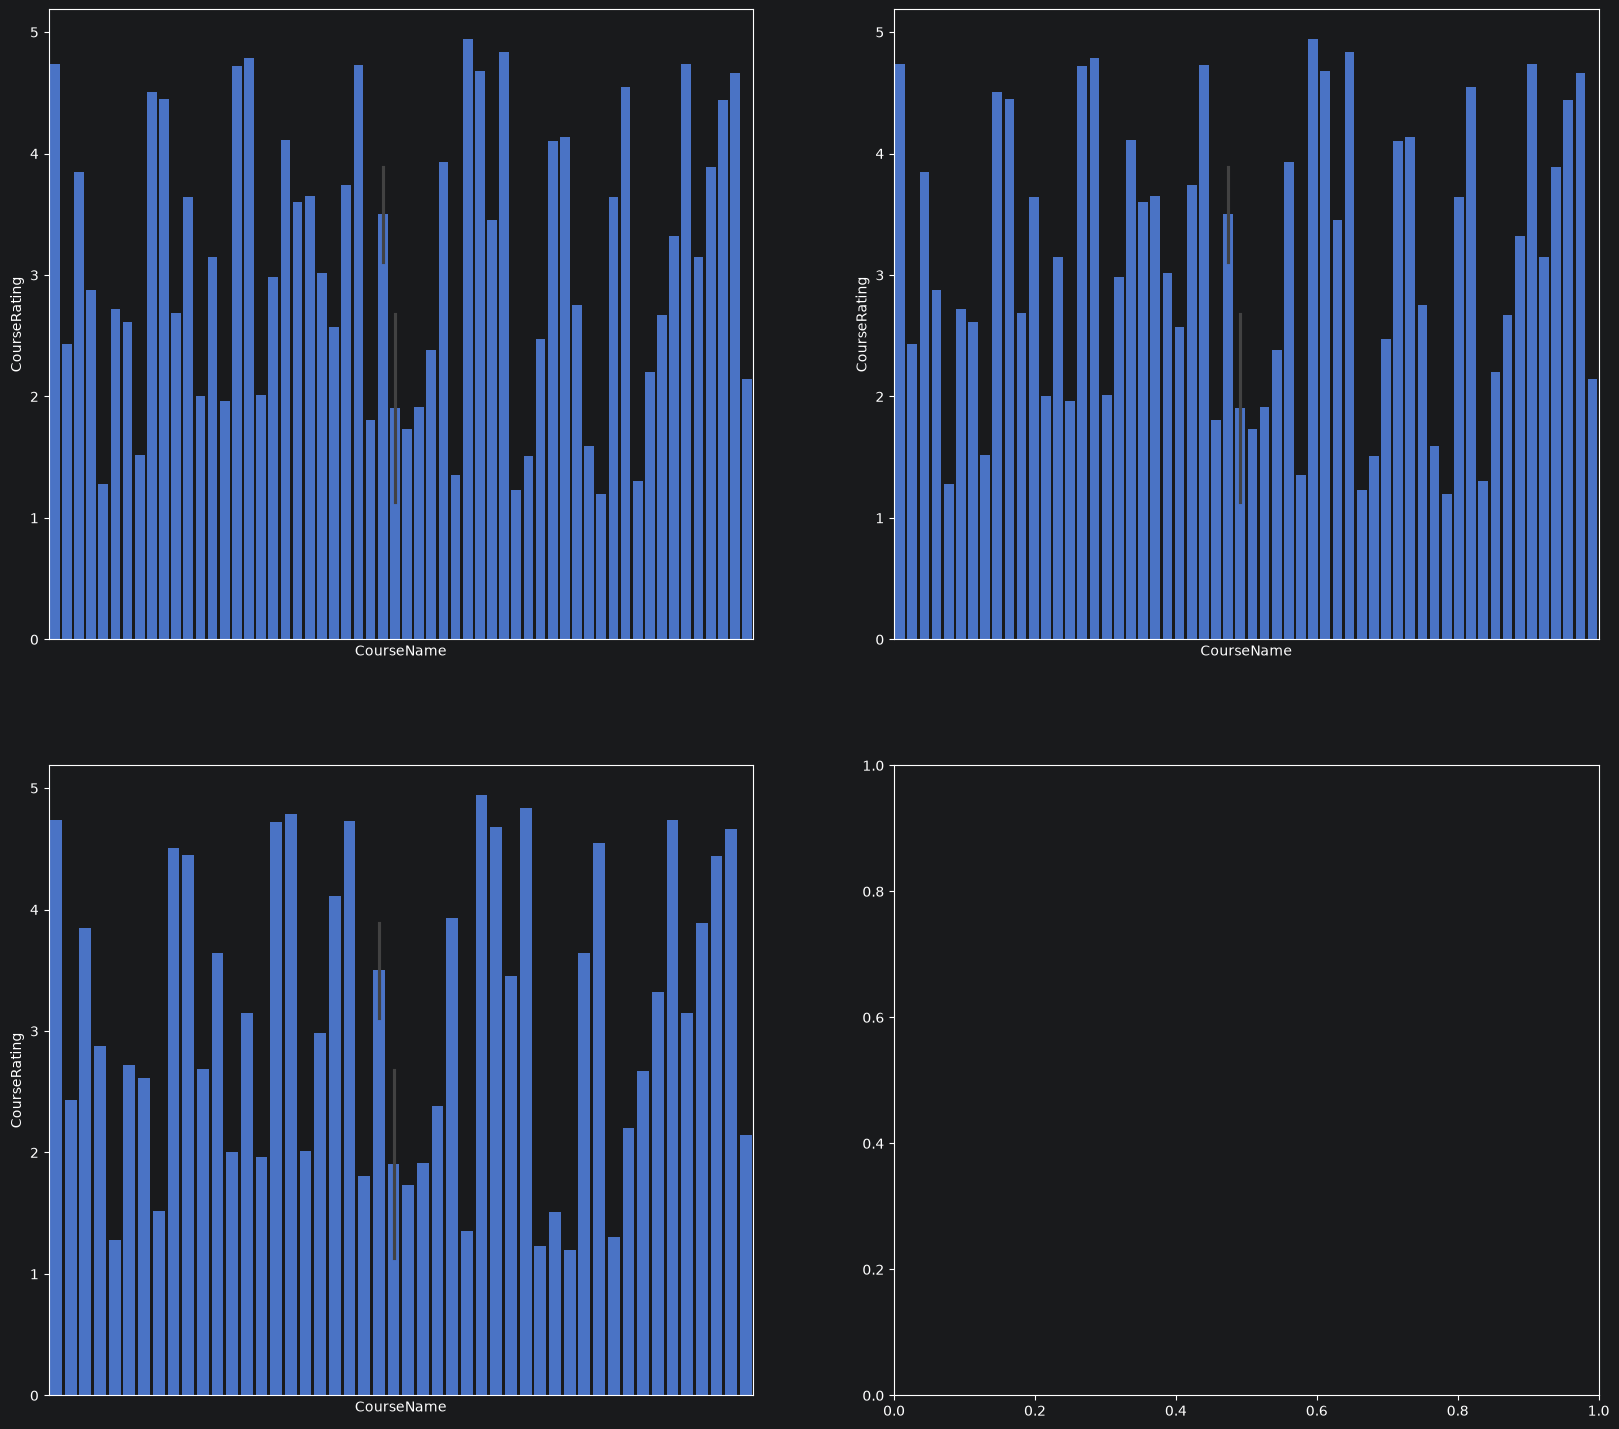

In [54]:
fig, ax = plt.subplots(nrows=2,ncols=2,figsize=(20,18))

sns.barplot(x=high_rated_teachers["CourseName"],y=high_rated_teachers["CourseRating"],ax=ax[0,0])
ax[0,0].set_xticks([])

sns.barplot(x=mid_rated_teachers["CourseName"],y=mid_rated_teachers["CourseRating"],ax=ax[0,1])
ax[0,1].set_xticks([])

sns.barplot(x=low_rated_teachers["CourseName"],y=low_rated_teachers["CourseRating"],ax=ax[1,0])
ax[1,0].set_xticks([])

We see that instructors of all three categories teach the same courses - all the three graphs show exactly the same pattern. Let us verify again by comparing each dataset with another.

In [55]:
print("Are courses taught by teachers of high rating same as those of mid rating?",end=" ")
print(bool((high_rated_teachers == mid_rated_teachers).sum().iloc[0] == high_rated_teachers.shape[0]))

print("Are courses taught by teachers of high rating same as those of mid rating?",end=" ")
print(bool((low_rated_teachers == mid_rated_teachers).sum().iloc[0] == low_rated_teachers.shape[0]))

print("Are courses taught by teachers of high rating same as those of mid rating?",end=" ")
print(bool((high_rated_teachers == low_rated_teachers).sum().iloc[0] == high_rated_teachers.shape[0]))

Are courses taught by teachers of high rating same as those of mid rating? True
Are courses taught by teachers of high rating same as those of mid rating? 

ValueError: Can only compare identically-labeled (both index and columns) DataFrame objects

In [56]:
print("Number of courses dealt by high quality teachers  : ",high_rated_teachers.shape[0])
print("Number of courses dealt by mid quality teachers   : ",mid_rated_teachers.shape[0])
print("Number of courses dealt by low quality teachers   : ",low_rated_teachers.shape[0])

Number of courses dealt by high quality teachers  :  60
Number of courses dealt by mid quality teachers   :  60
Number of courses dealt by low quality teachers   :  50


As we observe, although the patterns for courses taught by teachers of all three qualities are same, but the number of courses dealt with low quality teachers are less than those dealt by high quuality and mid quality teachers.

**Enrolment volume comparison by instructor rating tier**

This answers our fifth key analytical question - "Are highly rated instructors associated with higher enrolments?"

Here, we have to count the number of enrolments on courses dealt by teachers of three categories of ratings - low, mid, high.

In [57]:
teacher_names_with_ratings = df[["TeacherName","TeacherRating"]].value_counts().reset_index()
teacher_names_with_ratings.rename(columns={"count":"Enrolments"}, inplace=True)

teacher_names_with_ratings["Tier"] = list(map(lambda x: ("High" if x >= 4.0 else ("Mid" if x >= 2.0 else "Low")),teacher_names_with_ratings["TeacherRating"]))

teacher_names_with_ratings

,TeacherName,TeacherRating,Enrolments,Tier
0,Yolanda Levine,4.97,3061,High
1,Kimberly Miller,4.58,3025,High
2,Brenda Mercer,1.86,164,Low
3,Timothy Bailey,1.06,161,Low
4,Andrew Anderson,3.71,138,Mid
5,Wesley Garcia,4.04,137,High
6,Laurie Michael,1.55,133,Low
7,Steven Walker,3.54,133,Mid
8,Alexis Everett,3.95,123,Mid
9,Aaron Kirby,4.29,120,High


<Axes: xlabel='Tier', ylabel='Enrolments'>

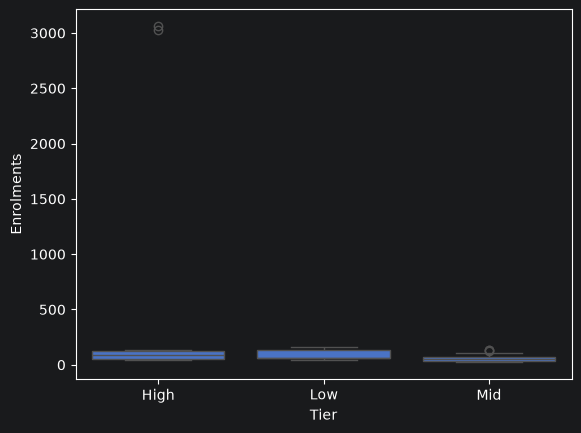

In [58]:
sns.boxplot(x=teacher_names_with_ratings["Tier"],y=teacher_names_with_ratings["Enrolments"])


In [59]:
teacher_names_with_ratings_1 = teacher_names_with_ratings[teacher_names_with_ratings["Enrolments"]<3000]

As we have a look at the above box plot, we cannot see the difference in how enrolments are distributed, just because of two outlier instructors who deal with more than 3000 courses

In [60]:
min_value = teacher_names_with_ratings_1["Enrolments"].min()
max_value = teacher_names_with_ratings_1["Enrolments"].max() + 50

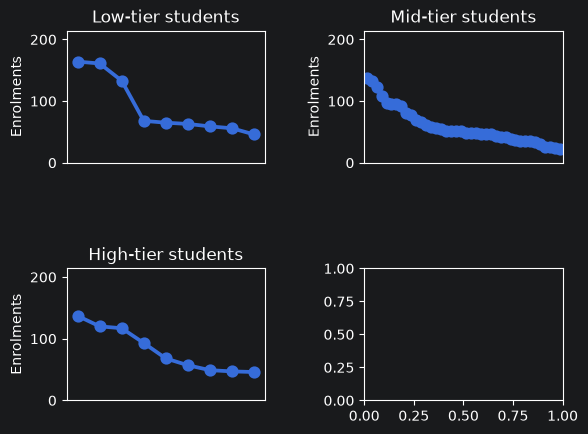

In [61]:
fig, ax = plt.subplots(nrows=2,ncols=2)
fig.subplots_adjust(hspace=0.8, wspace=0.5)

i = 0
j = 0
for k in ["Low","Mid","High"]:
    tr = teacher_names_with_ratings_1[teacher_names_with_ratings_1["Tier"]==k]["Enrolments"].sort_values()
    sns.pointplot(tr,ax=ax[i,j],)
    ax[i,j].set_xticks([])
    ax[i,j].set_title(k+"-tier students")
    ax[i,j].set_ylim([0,max_value])
    j += 1
    if j == 2:
        i += 1
        j = 0

The above point plots are on teachers teaching courses with less than 3000 enrolments. There are only 2 high-rated instructors who taught courses with more than 3000 enrolments. As we have a look at the above point plots, the following are the conclusions that we can arrive at:

1) For low tier instructors, majority of the instructors teach courses with less than 100 enrolments. There are only three instructors who teach courses with more than 100 enrolments.
2) For mid-tier and high-tier instructors, we observe a regulated pattern of course enrolments - like if we sort the number of course enrolments by instructors in descending order, the graph is a regulated line graph, as displayed above. Despite this, they remain less than 150; except that for high-tier instructors in which there are 2 instructors with more than 3000 course enrolments.

Here, let us consider a key-performance indicator - enrolment influence ratio. It is the correlation of teacher rating and number of enrolments.

In [62]:
enrolment_influence_ratio = teacher_names_with_ratings[["TeacherRating","Enrolments"]].corr().loc["Enrolments","TeacherRating"]
enrolment_influence_ratio

np.float64(0.31828684507429883)

Let us calculate the enrolment influence ratio for instructors of each tier

In [63]:
enrolment_influence_ratio_high_quality = teacher_names_with_ratings[teacher_names_with_ratings["Tier"]=="High"][["TeacherRating","Enrolments"]].corr().loc["Enrolments","TeacherRating"].round(2)

enrolment_influence_ratio_mid_quality = teacher_names_with_ratings[teacher_names_with_ratings["Tier"]=="Mid"][["TeacherRating","Enrolments"]].corr().loc["Enrolments","TeacherRating"].round(2)

enrolment_influence_ratio_low_quality = teacher_names_with_ratings[teacher_names_with_ratings["Tier"]=="Low"][["TeacherRating","Enrolments"]].corr().loc["Enrolments","TeacherRating"].round(2)

print("Enrolment Influence Ratio for High Quality Instructors : ",enrolment_influence_ratio_high_quality)
print("Enrolment Influence Ratio for Mid Quality Instructors  : ",enrolment_influence_ratio_mid_quality)
print("Enrolment Influence Ratio for Low Quality Instructors  : ",enrolment_influence_ratio_low_quality)


Enrolment Influence Ratio for High Quality Instructors :  0.83
Enrolment Influence Ratio for Mid Quality Instructors  :  0.03
Enrolment Influence Ratio for Low Quality Instructors  :  0.09


As we have a look at the above results, the number of enrolments seems to be significantly dependent with the instructor quality only for high quality instructors. For the mid and low quality teachers, there is hardly any influence of teacher rating with the enrolments.

We forgot to consider one thing. There are two high-quality instructors who deal with courses with more than 3000 enrolments. Let us check the enrolment influence ratio for high quality instructors excluding these two.

In [64]:
enrolment_influence_ratio_high_quality_1 = teacher_names_with_ratings_1[teacher_names_with_ratings_1["Tier"]=="High"][["TeacherRating","Enrolments"]].corr().loc["Enrolments","TeacherRating"].round(2)

print("Enrolment Influence Ratio for High Quality Instructors : ",enrolment_influence_ratio_high_quality_1)

Enrolment Influence Ratio for High Quality Instructors :  -0.36


Now, we see that the quality of instructor has some influence on the number of course enrolments but in a negative way.

Now, coming back to our key analytical question - "Are highly rated instructors associated with higher enrollments?", the answer is mostly no (there are two high rated teachers who teach courses with more than 3000 enrolments - the quality of rest of the teachers has negative correlation with number of enrolments).

Now, let us go ahead with analysing the quality of courses by instructor expertise. This in turn solves the fourth key analytical question - "Which expertise areas consistently deliver high-quality courses?"

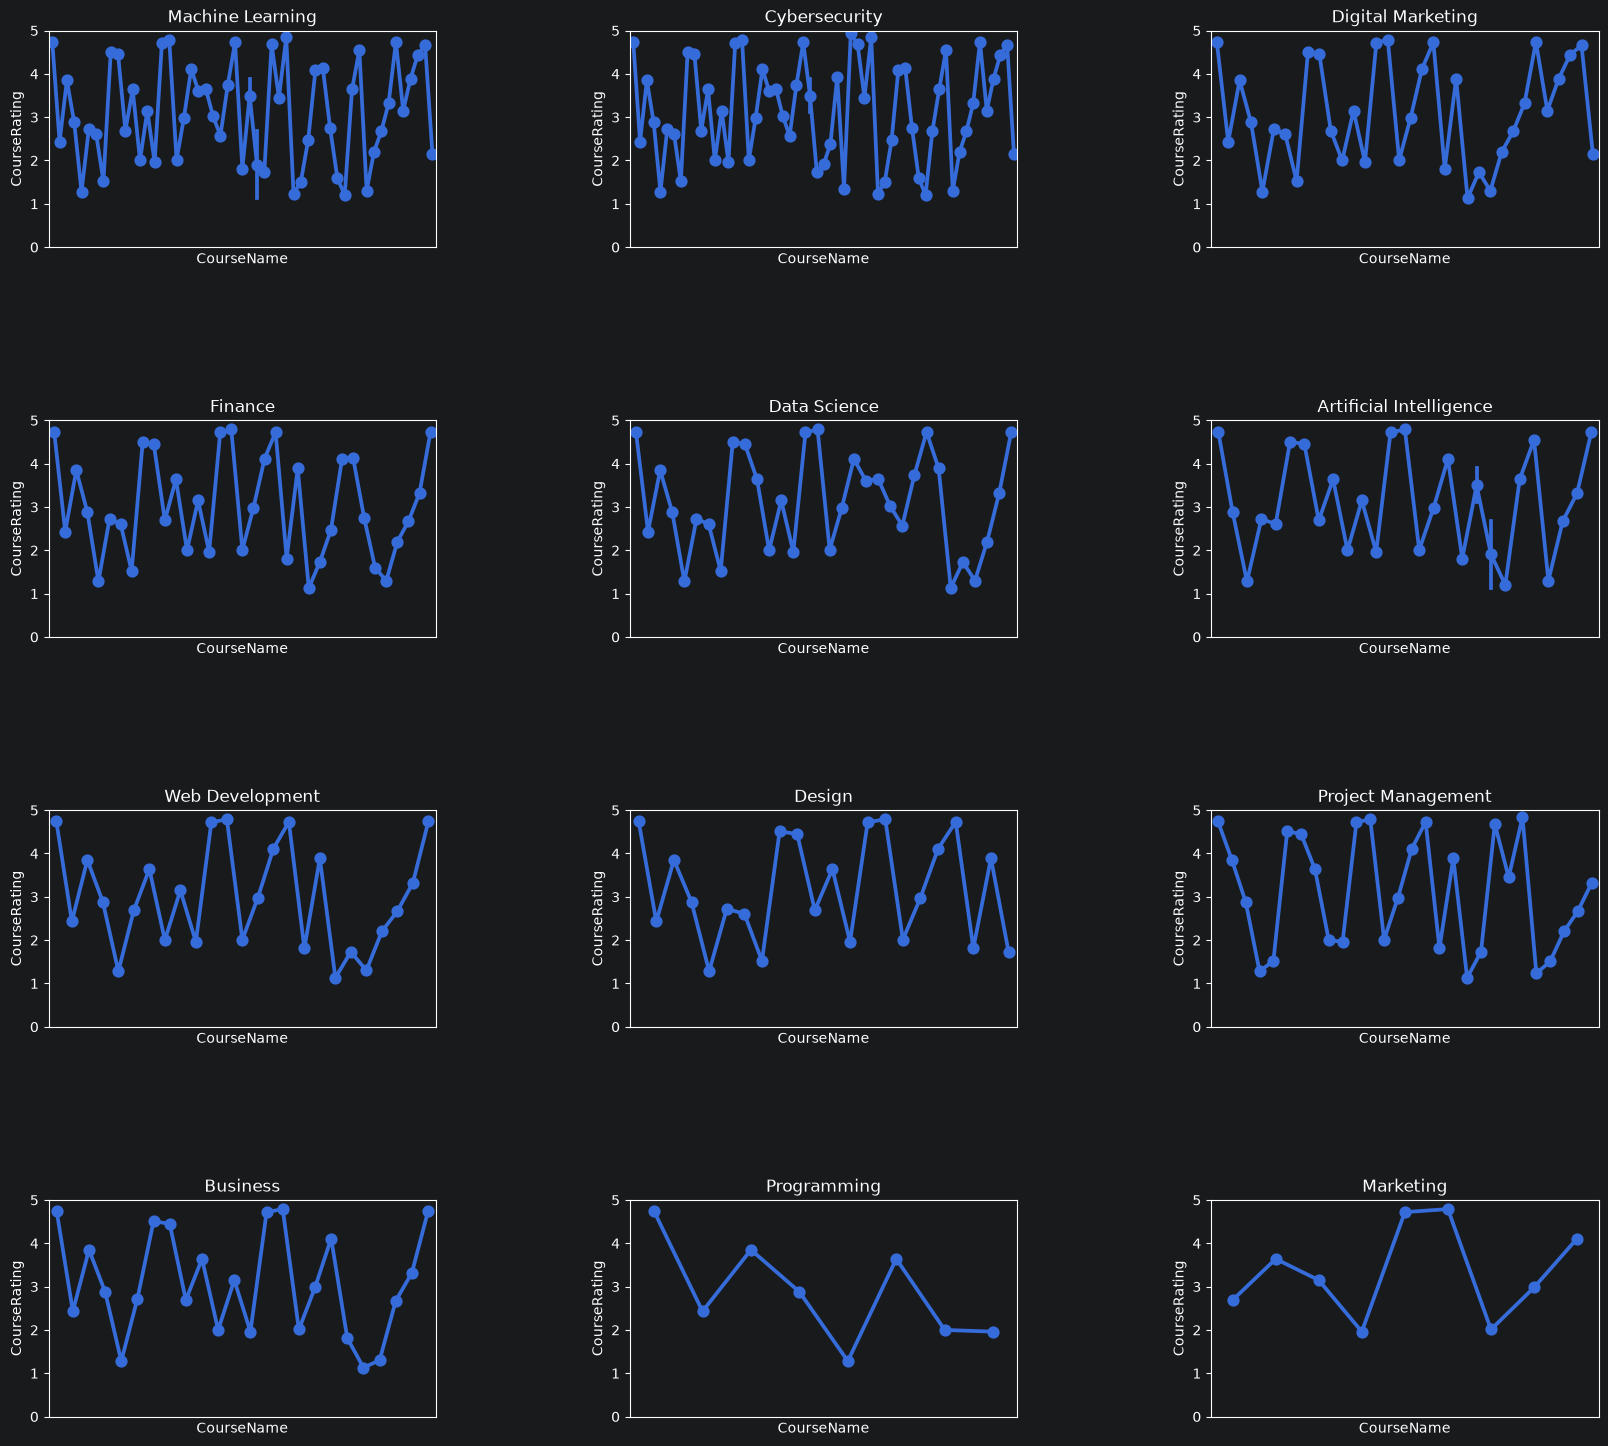

In [73]:
nrows = 4
ncols = len(df["Expertise"].unique())//nrows

list_of_expertises = df["Expertise"].unique()

fig, ax = plt.subplots(nrows=nrows,ncols=ncols,figsize=(20,18))
fig.subplots_adjust(hspace=0.8, wspace=0.5)

ctr = 0
for (i,j) in list(itertools.product(range(nrows),range(ncols))):
    expertise = list_of_expertises[ctr]
    lf = df[df["Expertise"]==expertise][["CourseName","CourseRating"]].drop_duplicates(ignore_index=True)
    sns.pointplot(x=lf["CourseName"],y=lf["CourseRating"],ax=ax[i,j])#,drawstyle="steps-post",lw=4)
    #for k, val in zip(lf["CourseName"].values,lf["CourseRating"].values):
    #    ax[i,j].text(k,val+0.5,str(val),ha="center",va="top",fontsize=6)
    ax[i,j].set_title(expertise)
    ax[i,j].set_xticks([])
    ax[i,j].set_ylim(0,5)


    ctr += 1

As we have a look at the above graphs, we see that no expertise delivers high-quality courses consistently. Let us calculate average course rating and rating Consistency index for each expertise.

In [66]:
q1 = df.groupby("Expertise")["CourseRating"].mean().round(2).reset_index().rename(columns={"CourseRating":"Average Course Rating"})
q2 = df.groupby("Expertise")["CourseRating"].std().round(2).reset_index().rename(columns={"CourseRating":"Rating Consistency Index"})

expertise_vs_quality = pd.merge(left=q1,right=q2,how="inner",on="Expertise")
expertise_vs_quality

,Expertise,Average Course Rating,Rating Consistency Index
0,Artificial Intelligence,3.16,1.08
1,Business,2.79,0.78
2,Cybersecurity,3.13,1.17
3,Data Science,3.28,0.70
4,Design,3.18,1.15
5,Digital Marketing,3.55,1.05
6,Finance,3.15,1.06
7,Machine Learning,3.05,1.19
8,Marketing,3.65,1.05
9,Programming,2.98,1.18


If we have a look at the rating consistency indices above, the standard deviations are so significant that none of the expertises have consistent ratings.

 **Identifying domains where teaching quality is most critical**

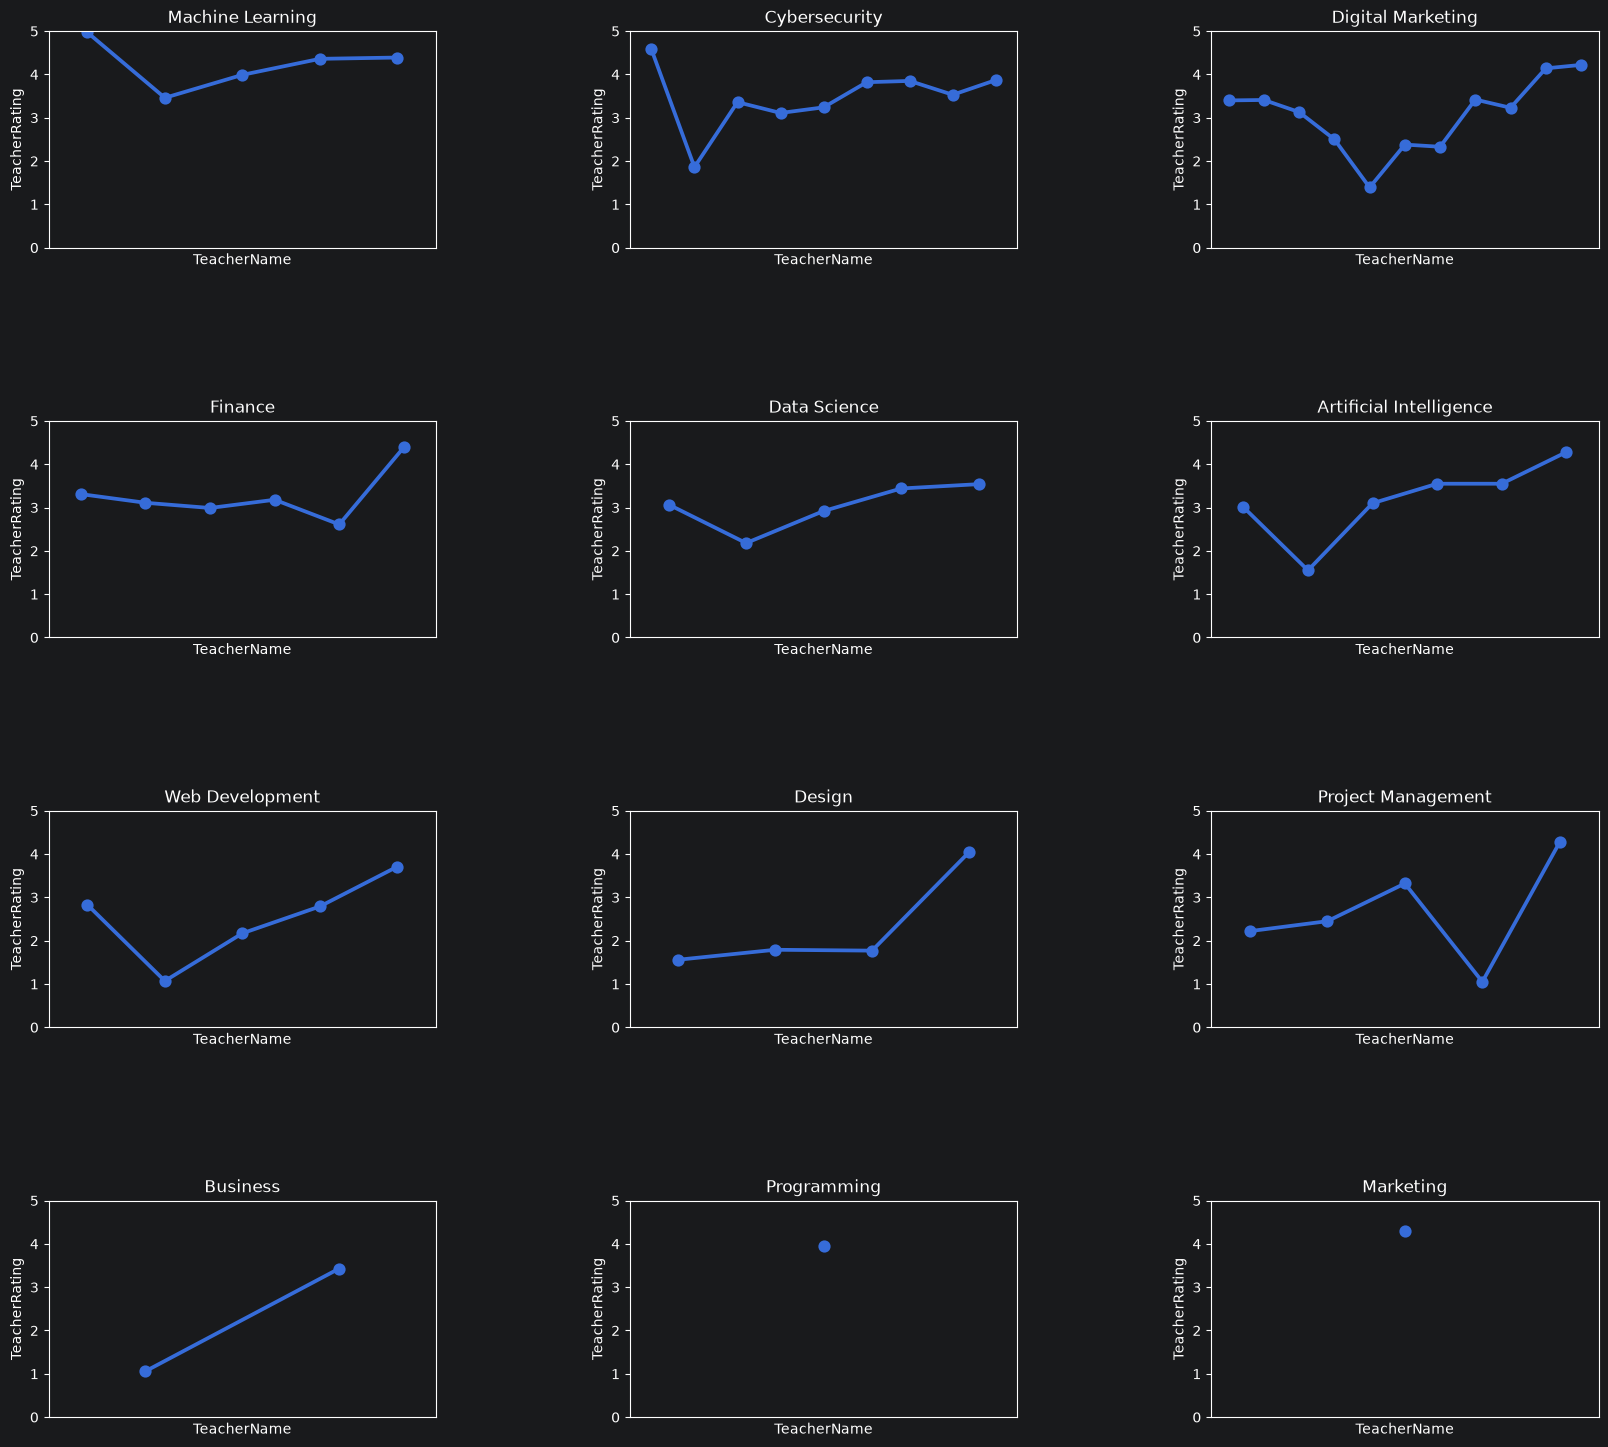

In [67]:
nrows = 4
ncols = len(df["Expertise"].unique())//nrows

list_of_expertises_teaching_quality = df["Expertise"].unique()

fig, ax = plt.subplots(nrows=nrows,ncols=ncols,figsize=(20,18))
fig.subplots_adjust(hspace=0.8, wspace=0.5)

ctr = 0
for (i,j) in list(itertools.product(range(nrows),range(ncols))):
    expertise = list_of_expertises_teaching_quality[ctr]
    lf = df[df["Expertise"]==expertise][["TeacherName","TeacherRating"]].drop_duplicates(ignore_index=True)
    sns.pointplot(x=lf["TeacherName"],y=lf["TeacherRating"],ax=ax[i,j])#,drawstyle="steps-post",lw=4)
    #for k, val in zip(lf["CourseName"].values,lf["CourseRating"].values):
    #    ax[i,j].text(k,val+0.5,str(val),ha="center",va="top",fontsize=6)
    ax[i,j].set_title(expertise)
    ax[i,j].set_xticks([])
    ax[i,j].set_ylim(0,5)

    ctr += 1

Let us also calculate Average Teacher Rating and Enrolment Influence Ratio for each teacher.

In [68]:
t1 = df.groupby(by="Expertise")["TeacherRating"].mean().round(2).reset_index().rename(columns={"TeacherRating":"Average Teacher Rating"})
t2 = df["Expertise"].value_counts().reset_index().rename(columns={"count":"Enrolments"})
atr_eir = pd.merge(left=t1,right=t2,how="inner",on="Expertise")
p = 0
for i in atr_eir["Expertise"].unique():
    atr_eir.loc[p,"Enrolment Influence Ratio"] = df[df["Expertise"]==i][["TeacherName","TeacherRating"]].value_counts().reset_index().set_index("TeacherName").corr().iloc[1,0]
    atr_eir.loc[p,"Number of Instructors"] = int(len(df[df["Expertise"]==i]["TeacherName"].unique()))
    p += 1
atr_eir["Enrolment Influence Ratio"] = atr_eir["Enrolment Influence Ratio"].round(2)
atr_eir = atr_eir.sort_values(by="Average Teacher Rating",ascending=False).reset_index(drop=True)
atr_eir

,Expertise,Average Teacher Rating,Enrolments,Enrolment Influence Ratio,Number of Instructors
0,Machine Learning,4.89,3303,0.73,5.0
1,Cybersecurity,4.37,3450,0.53,9.0
2,Marketing,4.29,120,NaN,1.0
3,Programming,3.95,123,NaN,1.0
4,Finance,3.38,410,0.47,6.0
5,Data Science,3.05,432,0.13,5.0
6,Digital Marketing,3.04,479,-0.04,11.0
7,Project Management,2.84,368,0.73,5.0
8,Web Development,2.80,344,0.65,5.0
9,Artificial Intelligence,2.80,389,-0.92,6.0


Let us exclude Marketing and Programming, because they have only one expertise. There are two expertise domains where quality of instructors matter the most. They are none other than Machine Learning and Cybersecurity.

The following are the expertise gaps or training needs:

1) There is only one instructor in each of Marketing and Programming domains. There needs to be more instructors in these two domains.
2) Most domains have around 5 or 6 instructors each. More niche courses need to be introduced in these expertises so that more instructors can teach these courses.
3) Artificial Intelligence (AI) is the only domain in which quality of courses vary negatively by enrolments. This means that number of enrolments for AI courses decreases as quality of instructors go up. This is not the case in the real-world. AI is a very booming tech domain. There needs to be more courses and more instructors in AI domain.